 <div align="center">

# 🩺 **IRIS — Eye Disease Detection Using Deep Learning**

### Deep Learning Analysis of Retinal Images for Diabetic Retinopathy Classification and Lesion Segmentation

<img src="https://i.postimg.cc/VNys5dWD/Glaucoma-Protecting-Your-Sight-from-a-Silent.jpg" width="800">

</div>

---

## **📌 Project Overview**

IRIS (Intelligent Retinal Image Screening) is a medical computer vision project that applies Deep Learning techniques to retinal fundus images to classify diabetic retinopathy severity and identify retinal lesions.

The project uses retinal images from the **Indian Diabetic Retinopathy Image Dataset (IDRiD)** to explore visual patterns associated with diabetic retinopathy, a diabetes-related eye disease that can damage the retina.

The project combines **Exploratory Data Analysis (EDA), Supervised Deep Learning, and Image Segmentation** to study retinal images, classify disease severity, and visualize lesion regions.

EfficientNet-B0 is planned for disease severity classification, while U-Net is planned for retinal lesion segmentation using suitable expert-annotated masks.

---

## **🎯 Objectives**

- Understand the structure and characteristics of the IDRiD dataset.
- Explore retinal images and their corresponding annotations.
- Perform data quality checks and inspect missing or invalid labels.
- Analyze the distribution of diabetic retinopathy severity grades.
- Visualize retinal images and lesion annotations.
- Preprocess and resize images for Deep Learning models.
- Apply **EfficientNet-B0** to classify diabetic retinopathy severity into five grades (0–4).
- Apply **U-Net** to segment retinal lesions using available pixel-level annotations.
- Evaluate classification and segmentation models using appropriate performance metrics.
- Use **Grad-CAM** to visualize image regions influencing classification predictions.
- Compare model performance and identify limitations.
- Develop a prototype workflow for retinal image screening.

---

## **📊 Dataset**

The project uses the **Indian Diabetic Retinopathy Image Dataset (IDRiD)**, which contains retinal fundus images and annotations for diabetic retinopathy research.

The dataset includes:

- **Retinal Fundus Images:** Color photographs of the retina.
- **Disease Grading Labels:** Image-level diabetic retinopathy severity grades.
- **Lesion Segmentation Masks:** Pixel-level annotations for specific retinal abnormalities.
- **Lesion Localization Annotations:** Information identifying the locations of retinal lesions.

The classification task uses five diabetic retinopathy severity grades:

| Grade | Description |
|---|---|
| 0 | No diabetic retinopathy |
| 1 | Mild |
| 2 | Moderate |
| 3 | Severe |
| 4 | Proliferative diabetic retinopathy |

The segmentation task focuses on identifying annotated retinal lesions, such as microaneurysms, hemorrhages, hard exudates, and soft exudates, where the relevant masks are available.

---

## **🛠️ Tools & Technologies**

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- OpenCV
- TensorFlow / Keras
- Scikit-learn
- Google Colab
- Deep Learning
- Convolutional Neural Networks (CNNs)

---

## **🤖 Deep Learning Techniques**

### **1. EfficientNet-B0 — Image Classification**

Used to classify retinal fundus images into five diabetic retinopathy severity grades, from Grade 0 to Grade 4.

Transfer learning will be explored to leverage pretrained image features and improve training efficiency.

### **2. U-Net — Image Segmentation**

Used to predict pixel-level retinal lesion masks from fundus images. The model will be trained and evaluated using the appropriate expert-annotated segmentation data.

### **3. Grad-CAM — Model Explainability**

Used to generate heatmaps highlighting image regions that influence EfficientNet-B0's classification predictions.

Grad-CAM is an explainability technique, not a separate predictive model.

---

## **📈 Expected Outcome**

The project aims to develop a Deep Learning prototype that classifies diabetic retinopathy severity, visualizes retinal lesion regions, and provides interpretable model outputs.

The analysis demonstrates practical skills in medical image preprocessing, exploratory data analysis, CNN-based image classification, semantic segmentation, transfer learning, model evaluation, and explainable AI.

**Note:** IRIS is an educational and research prototype, not a clinically validated diagnostic system. Its predictions must not replace professional ophthalmic assessment.


**Phase 1 — Dataset Loading and Understanding**

In [2]:
!pip install -q kaggle

In [3]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [4]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("/content/kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle setup completed!")

Kaggle setup completed!


In [5]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("/content/kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle setup completed!")

Kaggle setup completed!


In [6]:
!mkdir -p /content/iris_data

!kaggle datasets download \
    -d aaryapatel98/indian-diabetic-retinopathy-image-dataset \
    -p /content/iris_data

Dataset URL: https://www.kaggle.com/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 408M/408M [00:24<00:00, 17.8MB/s]



In [7]:
!mkdir -p /content/iris_data/extracted

!unzip -q /content/iris_data/indian-diabetic-retinopathy-image-dataset.zip \
    -d /content/iris_data/extracted

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [8]:
import os

base_path = "/content/iris_data/extracted"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:8]:
            print("  " * (level + 1) + file)

extracted/
  A.%20Segmentation/
    A. Segmentation/
      LICENSE.txt
      CC-BY-4.0.txt
      1. Original Images/
      2. All Segmentation Groundtruths/
  B.%20Disease%20Grading/
    B. Disease Grading/
      LICENSE.txt
      CC-BY-4.0.txt
      2. Groundtruths/
        a. IDRiD_Disease Grading_Training Labels.csv
        b. IDRiD_Disease Grading_Testing Labels.csv
      1. Original Images/
  C.%20Localization/
    C. Localization/
      LICENSE.txt
      CC-BY-4.0.txt
      2. Groundtruths/
      1. Original Images/


In [9]:
# Step 1: Set the Dataset Paths

import os

BASE_PATH = "/content/iris_data/extracted"

GRADING_PATH = os.path.join(
    BASE_PATH,
    "B.%20Disease%20Grading",
    "B. Disease Grading"
)

SEGMENTATION_PATH = os.path.join(
    BASE_PATH,
    "A.%20Segmentation",
    "A. Segmentation"
)

LOCALIZATION_PATH = os.path.join(
    BASE_PATH,
    "C.%20Localization",
    "C. Localization"
)

print("Grading folder exists:", os.path.exists(GRADING_PATH))
print("Segmentation folder exists:", os.path.exists(SEGMENTATION_PATH))
print("Localization folder exists:", os.path.exists(LOCALIZATION_PATH))

Grading folder exists: True
Segmentation folder exists: True
Localization folder exists: True


In [10]:
# Step 2: Load and Inspect Disease Grading CSV Files

import pandas as pd
import os

train_csv = os.path.join(
    GRADING_PATH,
    "2. Groundtruths",
    "a. IDRiD_Disease Grading_Training Labels.csv"
)

test_csv = os.path.join(
    GRADING_PATH,
    "2. Groundtruths",
    "b. IDRiD_Disease Grading_Testing Labels.csv"
)

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining dataset columns:")
print(train_df.columns.tolist())

print("\nFirst 5 training rows:")
display(train_df.head())

Training dataset shape: (413, 12)
Testing dataset shape: (103, 3)

Training dataset columns:
['Image name', 'Retinopathy grade', 'Risk of macular edema ', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']

First 5 training rows:


,Image name,Retinopathy grade,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,IDRiD_001,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IDRiD_004,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IDRiD_005,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Step 3: Check Missing Values and Disease Grade Distribution

print("Training dataset missing values:")
print(train_df.isnull().sum())

print("\nTesting dataset missing values:")
print(test_df.isnull().sum())

print("\nTraining retinopathy grade distribution:")
print(train_df["Retinopathy grade"].value_counts().sort_index())

print("\nTesting retinopathy grade distribution:")
print(test_df["Retinopathy grade"].value_counts().sort_index())

print("\nNon-empty Unnamed columns:")
unnamed_cols = [
    col for col in train_df.columns
    if col.startswith("Unnamed")
]

for col in unnamed_cols:
    if train_df[col].notna().any():
        print(col, "contains data")

print("Check completed!")

Training dataset missing values:
Image name                  0
Retinopathy grade           0
Risk of macular edema       0
Unnamed: 3                413
Unnamed: 4                413
Unnamed: 5                413
Unnamed: 6                413
Unnamed: 7                413
Unnamed: 8                413
Unnamed: 9                413
Unnamed: 10               413
Unnamed: 11               412
dtype: int64

Testing dataset missing values:
Image name                0
Retinopathy grade         0
Risk of macular edema     0
dtype: int64

Training retinopathy grade distribution:
Retinopathy grade
0    134
1     20
2    136
3     74
4     49
Name: count, dtype: int64

Testing retinopathy grade distribution:
Retinopathy grade
0    34
1     5
2    32
3    19
4    13
Name: count, dtype: int64

Non-empty Unnamed columns:
Unnamed: 11 contains data
Check completed!


In [12]:
# Step 4: Inspect Extra CSV Data and Image Folders

print("Non-empty values in Unnamed: 11:")
display(train_df.loc[train_df["Unnamed: 11"].notna()])

print("\nTraining image folder contents:")
train_image_path = os.path.join(
    GRADING_PATH, "1. Original Images", "a. Training Set"
)
print("Path:", train_image_path)
print("Folder exists:", os.path.exists(train_image_path))

if os.path.exists(train_image_path):
    print("Number of files:", len(os.listdir(train_image_path)))
    print("Sample files:", os.listdir(train_image_path)[:5])

print("\nTesting image folder contents:")
test_image_path = os.path.join(
    GRADING_PATH, "1. Original Images", "b. Testing Set"
)
print("Path:", test_image_path)
print("Folder exists:", os.path.exists(test_image_path))

if os.path.exists(test_image_path):
    print("Number of files:", len(os.listdir(test_image_path)))
    print("Sample files:", os.listdir(test_image_path)[:5])

Non-empty values in Unnamed: 11:


,Image name,Retinopathy grade,Risk of macular edema,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
404,IDRiD_405,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,



Training image folder contents:
Path: /content/iris_data/extracted/B.%20Disease%20Grading/B. Disease Grading/1. Original Images/a. Training Set
Folder exists: True
Number of files: 413
Sample files: ['IDRiD_153.jpg', 'IDRiD_257.jpg', 'IDRiD_122.jpg', 'IDRiD_249.jpg', 'IDRiD_068.jpg']

Testing image folder contents:
Path: /content/iris_data/extracted/B.%20Disease%20Grading/B. Disease Grading/1. Original Images/b. Testing Set
Folder exists: True
Number of files: 103
Sample files: ['IDRiD_068.jpg', 'IDRiD_066.jpg', 'IDRiD_006.jpg', 'IDRiD_003.jpg', 'IDRiD_033.jpg']


In [13]:
# Step 5: Clean the Disease Grading CSV Files

import pandas as pd

# Replace blank or whitespace-only values with missing values
train_df = train_df.replace(r"^\s*$", pd.NA, regex=True)
test_df = test_df.replace(r"^\s*$", pd.NA, regex=True)

# Remove columns that contain only missing values
train_df = train_df.dropna(axis=1, how="all")
test_df = test_df.dropna(axis=1, how="all")

# Remove extra spaces from column names
train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("Cleaned training dataset shape:", train_df.shape)
print("Cleaned testing dataset shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nMissing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in testing data:")
print(test_df.isnull().sum())

print("\nCSV cleaning completed!")

Cleaned training dataset shape: (413, 3)
Cleaned testing dataset shape: (103, 3)

Training columns:
['Image name', 'Retinopathy grade', 'Risk of macular edema']

Missing values in training data:
Image name               0
Retinopathy grade        0
Risk of macular edema    0
dtype: int64

Missing values in testing data:
Image name               0
Retinopathy grade        0
Risk of macular edema    0
dtype: int64

CSV cleaning completed!


In [14]:
# Step 6: Verify Image–Label Matching and Check Data Leakage

import os

# Get image filenames from folders
train_images = {
    f for f in os.listdir(train_image_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

test_images = {
    f for f in os.listdir(test_image_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

# Convert CSV image names to filenames
train_df["filename"] = train_df["Image name"].astype(str) + ".jpg"
test_df["filename"] = test_df["Image name"].astype(str) + ".jpg"

# Check whether CSV images exist in the folders
missing_train = set(train_df["filename"]) - train_images
missing_test = set(test_df["filename"]) - test_images

# Check overlap between the two image folders
overlap = train_images.intersection(test_images)

print("Training CSV rows:", len(train_df))
print("Training images in folder:", len(train_images))
print("Training images missing from folder:", len(missing_train))

print("\nTesting CSV rows:", len(test_df))
print("Testing images in folder:", len(test_images))
print("Testing images missing from folder:", len(missing_test))

print("\nImages shared between training and testing folders:", len(overlap))

print("\nVerification completed!")

Training CSV rows: 413
Training images in folder: 413
Training images missing from folder: 0

Testing CSV rows: 103
Testing images in folder: 103
Testing images missing from folder: 0

Images shared between training and testing folders: 103

Verification completed!


In [15]:
# Step 7: Compare Training and Testing Image Contents

import os
import hashlib

def get_file_hash(filepath):
    hasher = hashlib.md5()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

identical_images = []
different_images = []

for filename in sorted(train_images.intersection(test_images)):
    train_file = os.path.join(train_image_path, filename)
    test_file = os.path.join(test_image_path, filename)

    if get_file_hash(train_file) == get_file_hash(test_file):
        identical_images.append(filename)
    else:
        different_images.append(filename)

print("Matching filenames:", len(overlap))
print("Identical image files:", len(identical_images))
print("Different image files:", len(different_images))

print("\nSample identical files:", identical_images[:5])
print("Sample different files:", different_images[:5])

Matching filenames: 103
Identical image files: 0
Different image files: 103

Sample identical files: []
Sample different files: ['IDRiD_001.jpg', 'IDRiD_002.jpg', 'IDRiD_003.jpg', 'IDRiD_004.jpg', 'IDRiD_005.jpg']


In [16]:
# Step 8: Inspect Training and Testing Image Properties

from PIL import Image
import os

sample_names = sorted(overlap)[:5]

for filename in sample_names:
    train_file = os.path.join(train_image_path, filename)
    test_file = os.path.join(test_image_path, filename)

    with Image.open(train_file) as img:
        train_size = img.size
        train_format = img.format
        train_mode = img.mode

    with Image.open(test_file) as img:
        test_size = img.size
        test_format = img.format
        test_mode = img.mode

    print(f"\nImage: {filename}")
    print("Training:", train_size, train_format, train_mode)
    print("Testing: ", test_size, test_format, test_mode)


Image: IDRiD_001.jpg
Training: (4288, 2848) JPEG RGB
Testing:  (4288, 2848) JPEG RGB

Image: IDRiD_002.jpg
Training: (4288, 2848) JPEG RGB
Testing:  (4288, 2848) JPEG RGB

Image: IDRiD_003.jpg
Training: (4288, 2848) JPEG RGB
Testing:  (4288, 2848) JPEG RGB

Image: IDRiD_004.jpg
Training: (4288, 2848) JPEG RGB
Testing:  (4288, 2848) JPEG RGB

Image: IDRiD_005.jpg
Training: (4288, 2848) JPEG RGB
Testing:  (4288, 2848) JPEG RGB


In [17]:
# Step 9: Inspect Original Image Folder Structure

import os

original_images_path = os.path.join(
    GRADING_PATH, "1. Original Images"
)

for root, dirs, files in os.walk(original_images_path):
    print("\nFolder:", root)
    print("Number of image files:", len([
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]))
    print("Sample filenames:", files[:10])


Folder: /content/iris_data/extracted/B.%20Disease%20Grading/B. Disease Grading/1. Original Images
Number of image files: 0
Sample filenames: []

Folder: /content/iris_data/extracted/B.%20Disease%20Grading/B. Disease Grading/1. Original Images/b. Testing Set
Number of image files: 103
Sample filenames: ['IDRiD_068.jpg', 'IDRiD_066.jpg', 'IDRiD_006.jpg', 'IDRiD_003.jpg', 'IDRiD_033.jpg', 'IDRiD_008.jpg', 'IDRiD_095.jpg', 'IDRiD_073.jpg', 'IDRiD_055.jpg', 'IDRiD_092.jpg']

Folder: /content/iris_data/extracted/B.%20Disease%20Grading/B. Disease Grading/1. Original Images/a. Training Set
Number of image files: 413
Sample filenames: ['IDRiD_153.jpg', 'IDRiD_257.jpg', 'IDRiD_122.jpg', 'IDRiD_249.jpg', 'IDRiD_068.jpg', 'IDRiD_066.jpg', 'IDRiD_006.jpg', 'IDRiD_138.jpg', 'IDRiD_399.jpg', 'IDRiD_127.jpg']


In [18]:
# Step 10: Create Separate Training and Testing Image Paths

import os

# Build paths using each split's own image folder
train_df["image_path"] = train_df["Image name"].apply(
    lambda name: os.path.join(train_image_path, f"{name}.jpg")
)

test_df["image_path"] = test_df["Image name"].apply(
    lambda name: os.path.join(test_image_path, f"{name}.jpg")
)

# Verify all image paths exist
train_valid = train_df["image_path"].apply(os.path.isfile).all()
test_valid = test_df["image_path"].apply(os.path.isfile).all()

print("All training image paths valid:", train_valid)
print("All testing image paths valid:", test_valid)

print("\nTraining data sample:")
display(train_df[["Image name", "Retinopathy grade", "image_path"]].head())

print("\nTesting data sample:")
display(test_df[["Image name", "Retinopathy grade", "image_path"]].head())

All training image paths valid: True
All testing image paths valid: True

Training data sample:


,Image name,Retinopathy grade,image_path
0,IDRiD_001,3,/content/iris_data/extracted/B.%20Disease%20Gr...
1,IDRiD_002,3,/content/iris_data/extracted/B.%20Disease%20Gr...
2,IDRiD_003,2,/content/iris_data/extracted/B.%20Disease%20Gr...
3,IDRiD_004,3,/content/iris_data/extracted/B.%20Disease%20Gr...
4,IDRiD_005,4,/content/iris_data/extracted/B.%20Disease%20Gr...



Testing data sample:


,Image name,Retinopathy grade,image_path
0,IDRiD_001,4,/content/iris_data/extracted/B.%20Disease%20Gr...
1,IDRiD_002,4,/content/iris_data/extracted/B.%20Disease%20Gr...
2,IDRiD_003,4,/content/iris_data/extracted/B.%20Disease%20Gr...
3,IDRiD_004,4,/content/iris_data/extracted/B.%20Disease%20Gr...
4,IDRiD_005,4,/content/iris_data/extracted/B.%20Disease%20Gr...


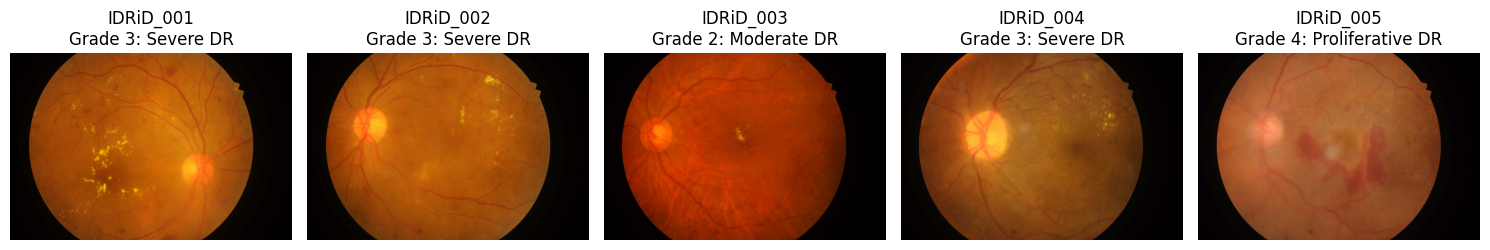

In [19]:
# Step 11: Visualize Sample Retinal Images

import matplotlib.pyplot as plt
from PIL import Image

# Retinopathy grade descriptions
grade_names = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR"
}

# Select 5 training images
sample_df = train_df.head(5)

plt.figure(figsize=(15, 5))

for i, (_, row) in enumerate(sample_df.iterrows()):
    image = Image.open(row["image_path"])

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(
        f'{row["Image name"]}\n'
        f'Grade {row["Retinopathy grade"]}: '
        f'{grade_names[row["Retinopathy grade"]]}'
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:

# Step 12: Prepare Images for Deep Learning

import numpy as np
from PIL import Image

# Select one training image
sample_row = train_df.iloc[0]
image_path = sample_row["image_path"]

# Open and resize the retinal image
image = Image.open(image_path).convert("RGB")
resized_image = image.resize((224, 224))

# Convert image to a NumPy array
image_array = np.array(resized_image)

# Normalize pixel values to the range 0–1
normalized_image = image_array / 255.0

print("Original image size:", image.size)
print("Resized image shape:", image_array.shape)
print("Normalized pixel range:",
      normalized_image.min(), "to", normalized_image.max())


Original image size: (4288, 2848)
Resized image shape: (224, 224, 3)
Normalized pixel range: 0.0 to 1.0


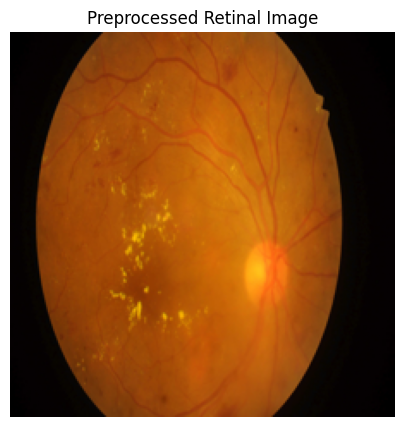

In [21]:

# Step 13: Visualize the Preprocessed Image

plt.figure(figsize=(5, 5))

plt.imshow(normalized_image)
plt.title("Preprocessed Retinal Image")
plt.axis("off")

plt.show()


In [22]:

# Step 14: Prepare Training Labels

# Convert retinopathy grades to integers
train_df["Retinopathy grade"] = train_df["Retinopathy grade"].astype(int)
test_df["Retinopathy grade"] = test_df["Retinopathy grade"].astype(int)

# Display the image filenames and their labels
print("Training labels:")
print(train_df[["Image name", "Retinopathy grade"]].head())

print("\nTesting labels:")
print(test_df[["Image name", "Retinopathy grade"]].head())

# Confirm the available classes
print("\nTraining classes:",
      sorted(train_df["Retinopathy grade"].unique()))

print("Testing classes:",
      sorted(test_df["Retinopathy grade"].unique()))


Training labels:
  Image name  Retinopathy grade
0  IDRiD_001                  3
1  IDRiD_002                  3
2  IDRiD_003                  2
3  IDRiD_004                  3
4  IDRiD_005                  4

Testing labels:
  Image name  Retinopathy grade
0  IDRiD_001                  4
1  IDRiD_002                  4
2  IDRiD_003                  4
3  IDRiD_004                  4
4  IDRiD_005                  4

Training classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Testing classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [23]:

# Step 15: Check TensorFlow and GPU

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available:", gpus)
else:
    print("No GPU detected. Training will use the CPU.")


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [24]:

# Step 16: Import Deep Learning Libraries

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("EfficientNet-B0 library loaded successfully!")


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
EfficientNet-B0 library loaded successfully!


In [25]:

# Step 17: Create a CSV-Based Image Data Pipeline

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_CLASSES = 5

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

train_paths = train_df["image_path"].values
train_labels = train_df["Retinopathy grade"].values.astype("int32")

test_paths = test_df["image_path"].values
test_labels = test_df["Retinopathy grade"].values.astype("int32")

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)
train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)
test_ds = test_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)


Training images: 413
Testing images: 103
Image size: (224, 224)
Batch size: 16


In [26]:

# Step 18: Verify the Image Batch

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Labels in this batch:", labels.numpy())
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))


Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels in this batch: [3 3 2 3 4 4 4 4 3 4 3 3 3 4 4 2]
Pixel value range: 0.0 to 255.0


In [27]:

# Step 19: Inspect Segmentation and Localization Data

print("SEGMENTATION FOLDER")
for folder in os.listdir(SEGMENTATION_PATH):
    folder_path = os.path.join(SEGMENTATION_PATH, folder)
    print(f"\n{folder}")

    if os.path.isdir(folder_path):
        print("Items:", os.listdir(folder_path)[:10])

print("\nLOCALIZATION FOLDER")
for folder in os.listdir(LOCALIZATION_PATH):
    folder_path = os.path.join(LOCALIZATION_PATH, folder)
    print(f"\n{folder}")

    if os.path.isdir(folder_path):
        print("Items:", os.listdir(folder_path)[:10])


SEGMENTATION FOLDER

LICENSE.txt

1. Original Images
Items: ['b. Testing Set', 'a. Training Set']

2. All Segmentation Groundtruths
Items: ['b. Testing Set', 'a. Training Set']

CC-BY-4.0.txt

LOCALIZATION FOLDER

LICENSE.txt

2. Groundtruths
Items: ['1. Optic Disc Center Location', '2. Fovea Center Location']

1. Original Images
Items: ['b. Testing Set', 'a. Training Set']

CC-BY-4.0.txt


In [28]:

# Step 20: Count Segmentation Images and Groundtruth Files

seg_original_path = os.path.join(
    SEGMENTATION_PATH, "1. Original Images"
)

seg_groundtruth_path = os.path.join(
    SEGMENTATION_PATH, "2. All Segmentation Groundtruths"
)

for split in ["a. Training Set", "b. Testing Set"]:
    image_folder = os.path.join(seg_original_path, split)
    mask_folder = os.path.join(seg_groundtruth_path, split)

    image_files = [
        f for f in os.listdir(image_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ]

    mask_files = [
        f for f in os.listdir(mask_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ]

    print(f"\n{split}")
    print("Original images:", len(image_files))
    print("Groundtruth files:", len(mask_files))
    print("Sample images:", image_files[:5])
    print("Sample groundtruths:", mask_files[:5])



a. Training Set
Original images: 54
Groundtruth files: 0
Sample images: ['IDRiD_39.jpg', 'IDRiD_36.jpg', 'IDRiD_51.jpg', 'IDRiD_43.jpg', 'IDRiD_28.jpg']
Sample groundtruths: []

b. Testing Set
Original images: 27
Groundtruth files: 0
Sample images: ['IDRiD_56.jpg', 'IDRiD_78.jpg', 'IDRiD_64.jpg', 'IDRiD_65.jpg', 'IDRiD_63.jpg']
Sample groundtruths: []


In [29]:

# Step 21: Inspect Segmentation Groundtruth Folder Structure

for split in ["a. Training Set", "b. Testing Set"]:
    mask_folder = os.path.join(seg_groundtruth_path, split)

    print(f"\n{split}")
    print("Folder path:", mask_folder)

    for root, dirs, files in os.walk(mask_folder):
        level = root.replace(mask_folder, "").count(os.sep)
        indent = "  " * level

        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}  {file}")

        if level >= 3:
            dirs[:] = []



a. Training Set
Folder path: /content/iris_data/extracted/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set
a. Training Set/
  5. Optic Disc/
    IDRiD_18_OD.tif
    IDRiD_46_OD.tif
    IDRiD_22_OD.tif
    IDRiD_42_OD.tif
    IDRiD_34_OD.tif
  2. Haemorrhages/
    IDRiD_14_HE.tif
    IDRiD_39_HE.tif
    IDRiD_07_HE.tif
    IDRiD_49_HE.tif
    IDRiD_48_HE.tif
  4. Soft Exudates/
    IDRiD_30_SE.tif
    IDRiD_53_SE.tif
    IDRiD_46_SE.tif
    IDRiD_50_SE.tif
    IDRiD_51_SE.tif
  1. Microaneurysms/
    IDRiD_07_MA.tif
    IDRiD_13_MA.tif
    IDRiD_21_MA.tif
    IDRiD_22_MA.tif
    IDRiD_02_MA.tif
  3. Hard Exudates/
    IDRiD_42_EX.tif
    IDRiD_16_EX.tif
    IDRiD_01_EX.tif
    IDRiD_30_EX.tif
    IDRiD_35_EX.tif

b. Testing Set
Folder path: /content/iris_data/extracted/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set
b. Testing Set/
  5. Optic Disc/
    IDRiD_60_OD.tif
    IDRiD_63_OD.tif
    IDRiD_70_OD.tif
    IDRiD_5

In [30]:

# Step 22: Count Groundtruth Masks by Category

for split in ["a. Training Set", "b. Testing Set"]:
    split_path = os.path.join(seg_groundtruth_path, split)

    print(f"\n{split}")

    for category in sorted(os.listdir(split_path)):
        category_path = os.path.join(split_path, category)

        if os.path.isdir(category_path):
            tif_files = [
                f for f in os.listdir(category_path)
                if f.lower().endswith((".tif", ".tiff"))
            ]

            print(f"{category}: {len(tif_files)} masks")



a. Training Set
1. Microaneurysms: 54 masks
2. Haemorrhages: 53 masks
3. Hard Exudates: 54 masks
4. Soft Exudates: 26 masks
5. Optic Disc: 54 masks

b. Testing Set
1. Microaneurysms: 27 masks
2. Haemorrhages: 27 masks
3. Hard Exudates: 27 masks
4. Soft Exudates: 14 masks
5. Optic Disc: 27 masks


In [31]:

# Step 23: Inspect Localization Groundtruths

localization_gt_path = os.path.join(
    LOCALIZATION_PATH, "2. Groundtruths"
)

for root, dirs, files in os.walk(localization_gt_path):
    level = root.replace(localization_gt_path, "").count(os.sep)
    indent = "  " * level

    print(f"\n{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")



2. Groundtruths/

  1. Optic Disc Center Location/
    b. IDRiD_OD_Center_Testing Set_Markups.csv
    a. IDRiD_OD_Center_Training Set_Markups.csv

  2. Fovea Center Location/
    IDRiD_Fovea_Center_Testing Set_Markups.csv
    IDRiD_Fovea_Center_Training Set_Markups.csv


In [32]:

# Step 24: Load and Inspect Localization CSVs

od_path = os.path.join(
    localization_gt_path,
    "1. Optic Disc Center Location"
)

fovea_path = os.path.join(
    localization_gt_path,
    "2. Fovea Center Location"
)

localization_files = {
    "Optic Disc Training": os.path.join(
        od_path, "a. IDRiD_OD_Center_Training Set_Markups.csv"
    ),
    "Optic Disc Testing": os.path.join(
        od_path, "b. IDRiD_OD_Center_Testing Set_Markups.csv"
    ),
    "Fovea Training": os.path.join(
        fovea_path, "IDRiD_Fovea_Center_Training Set_Markups.csv"
    ),
    "Fovea Testing": os.path.join(
        fovea_path, "IDRiD_Fovea_Center_Testing Set_Markups.csv"
    )
}

for name, path in localization_files.items():
    df = pd.read_csv(path)

    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))



Optic Disc Training
Shape: (515, 48)
Columns: ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47']


,Image No,X- Coordinate,Y - Coordinate,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47
0,IDRiD_001,2858.0,1805.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,943.0,1119.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,779.0,1269.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Optic Disc Testing
Shape: (515, 48)
Columns: ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47']


,Image No,X- Coordinate,Y - Coordinate,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47
0,IDRiD_001,651.0,1453.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,3158.0,1280.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,1101.0,1374.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Fovea Training
Shape: (515, 48)
Columns: ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47']


,Image No,X- Coordinate,Y - Coordinate,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47
0,IDRiD_001,1494.0,1970.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,2270.0,1329.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2109.0,1351.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Fovea Testing
Shape: (515, 48)
Columns: ['Image No', 'X- Coordinate', 'Y - Coordinate', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47']


,Image No,X- Coordinate,Y - Coordinate,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47
0,IDRiD_001,1914.0,1617.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDRiD_002,1922.0,1468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDRiD_003,2566.0,1591.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:

# Step 25: Clean and Validate Localization Data

localization_dfs = {}

for name, path in localization_files.items():
    df = pd.read_csv(path)

    # Remove blank cells and completely empty columns
    df = df.replace(r"^\s*$", pd.NA, regex=True)
    df = df.dropna(axis=1, how="all")
    df.columns = df.columns.str.strip()

    # Remove rows without an image identifier or coordinates
    df = df.dropna(
        subset=["Image No", "X- Coordinate", "Y - Coordinate"]
    )

    localization_dfs[name] = df

    print(f"\n{name}")
    print("Cleaned shape:", df.shape)
    print("Unique images:", df["Image No"].nunique())
    print("Missing values:")
    print(df[["Image No", "X- Coordinate", "Y - Coordinate"]].isna().sum())
    print("Sample records:")
    print(df[["Image No", "X- Coordinate", "Y - Coordinate"]].head(3))



Optic Disc Training
Cleaned shape: (413, 3)
Unique images: 413
Missing values:
Image No          0
X- Coordinate     0
Y - Coordinate    0
dtype: int64
Sample records:
    Image No  X- Coordinate  Y - Coordinate
0  IDRiD_001         2858.0          1805.0
1  IDRiD_002          943.0          1119.0
2  IDRiD_003          779.0          1269.0

Optic Disc Testing
Cleaned shape: (103, 3)
Unique images: 103
Missing values:
Image No          0
X- Coordinate     0
Y - Coordinate    0
dtype: int64
Sample records:
    Image No  X- Coordinate  Y - Coordinate
0  IDRiD_001          651.0          1453.0
1  IDRiD_002         3158.0          1280.0
2  IDRiD_003         1101.0          1374.0

Fovea Training
Cleaned shape: (413, 3)
Unique images: 413
Missing values:
Image No          0
X- Coordinate     0
Y - Coordinate    0
dtype: int64
Sample records:
    Image No  X- Coordinate  Y - Coordinate
0  IDRiD_001         1494.0          1970.0
1  IDRiD_002         2270.0          1329.0
2  IDRiD_003   

In [34]:
# Step 26: Validate Localization Coordinates

for name, df in localization_dfs.items():
    invalid_x = ((df["X- Coordinate"] < 0) |
                 (df["X- Coordinate"] >= 4288)).sum()

    invalid_y = ((df["Y - Coordinate"] < 0) |
                 (df["Y - Coordinate"] >= 2848)).sum()

    print(f"\n{name}")
    print("Invalid X coordinates:", invalid_x)
    print("Invalid Y coordinates:", invalid_y)


Optic Disc Training
Invalid X coordinates: 0
Invalid Y coordinates: 0

Optic Disc Testing
Invalid X coordinates: 0
Invalid Y coordinates: 0

Fovea Training
Invalid X coordinates: 0
Invalid Y coordinates: 0

Fovea Testing
Invalid X coordinates: 0
Invalid Y coordinates: 0


In [35]:
# Step 27: Inspect Segmentation Image and Mask Filenames

for split in ["a. Training Set", "b. Testing Set"]:
    image_folder = os.path.join(
        SEGMENTATION_PATH, "1. Original Images", split
    )

    print(f"\n{split}")
    print("Sample image files:",
          sorted(os.listdir(image_folder))[:5])

    for lesion in [
        "1. Microaneurysms",
        "2. Haemorrhages",
        "3. Hard Exudates",
        "4. Soft Exudates",
        "5. Optic Disc"
    ]:
        mask_folder = os.path.join(
            SEGMENTATION_PATH,
            "2. All Segmentation Groundtruths",
            split,
            lesion
        )

        print(f"{lesion}:",
              sorted(os.listdir(mask_folder))[:3])


a. Training Set
Sample image files: ['IDRiD_01.jpg', 'IDRiD_02.jpg', 'IDRiD_03.jpg', 'IDRiD_04.jpg', 'IDRiD_05.jpg']
1. Microaneurysms: ['IDRiD_01_MA.tif', 'IDRiD_02_MA.tif', 'IDRiD_03_MA.tif']
2. Haemorrhages: ['IDRiD_01_HE.tif', 'IDRiD_02_HE.tif', 'IDRiD_03_HE.tif']
3. Hard Exudates: ['IDRiD_01_EX.tif', 'IDRiD_02_EX.tif', 'IDRiD_03_EX.tif']
4. Soft Exudates: ['IDRiD_03_SE.tif', 'IDRiD_08_SE.tif', 'IDRiD_13_SE.tif']
5. Optic Disc: ['IDRiD_01_OD.tif', 'IDRiD_02_OD.tif', 'IDRiD_03_OD.tif']

b. Testing Set
Sample image files: ['IDRiD_55.jpg', 'IDRiD_56.jpg', 'IDRiD_57.jpg', 'IDRiD_58.jpg', 'IDRiD_59.jpg']
1. Microaneurysms: ['IDRiD_55_MA.tif', 'IDRiD_56_MA.tif', 'IDRiD_57_MA.tif']
2. Haemorrhages: ['IDRiD_55_HE.tif', 'IDRiD_56_HE.tif', 'IDRiD_57_HE.tif']
3. Hard Exudates: ['IDRiD_55_EX.tif', 'IDRiD_56_EX.tif', 'IDRiD_57_EX.tif']
4. Soft Exudates: ['IDRiD_55_SE.tif', 'IDRiD_56_SE.tif', 'IDRiD_59_SE.tif']
5. Optic Disc: ['IDRiD_55_OD.tif', 'IDRiD_56_OD.tif', 'IDRiD_57_OD.tif']


In [36]:
# Step 28: Check Image-Mask Matching

lesions = {
    "Microaneurysms": "_MA.tif",
    "Haemorrhages": "_HE.tif",
    "Hard Exudates": "_EX.tif",
    "Soft Exudates": "_SE.tif",
    "Optic Disc": "_OD.tif"
}

for split in ["a. Training Set", "b. Testing Set"]:
    image_folder = os.path.join(
        SEGMENTATION_PATH, "1. Original Images", split
    )

    image_ids = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_folder)
        if f.lower().endswith(".jpg")
    }

    print(f"\n{split} — Total images: {len(image_ids)}")

    for lesion, suffix in lesions.items():
        mask_folder = os.path.join(
            SEGMENTATION_PATH,
            "2. All Segmentation Groundtruths",
            split,
            {
                "Microaneurysms": "1. Microaneurysms",
                "Haemorrhages": "2. Haemorrhages",
                "Hard Exudates": "3. Hard Exudates",
                "Soft Exudates": "4. Soft Exudates",
                "Optic Disc": "5. Optic Disc"
            }[lesion]
        )

        mask_ids = {
            f.replace(suffix, "")
            for f in os.listdir(mask_folder)
            if f.endswith(suffix)
        }

        matched = image_ids & mask_ids
        print(
            f"{lesion}: {len(matched)}/{len(image_ids)} images matched"
        )


a. Training Set — Total images: 54
Microaneurysms: 54/54 images matched
Haemorrhages: 53/54 images matched
Hard Exudates: 54/54 images matched
Soft Exudates: 26/54 images matched
Optic Disc: 54/54 images matched

b. Testing Set — Total images: 27
Microaneurysms: 27/27 images matched
Haemorrhages: 27/27 images matched
Hard Exudates: 27/27 images matched
Soft Exudates: 14/27 images matched
Optic Disc: 27/27 images matched


In [37]:
# Step 29: Check Original Image and Mask Dimensions

from PIL import Image

split = "a. Training Set"

image_folder = os.path.join(
    SEGMENTATION_PATH, "1. Original Images", split
)

mask_folder = os.path.join(
    SEGMENTATION_PATH,
    "2. All Segmentation Groundtruths",
    split,
    "1. Microaneurysms"
)

image_file = sorted(os.listdir(image_folder))[0]
mask_file = sorted(os.listdir(mask_folder))[0]

image = Image.open(os.path.join(image_folder, image_file))
mask = Image.open(os.path.join(mask_folder, mask_file))

print("Original image:", image_file)
print("Original image dimensions:", image.size)
print("Original image mode:", image.mode)

print("\nMask image:", mask_file)
print("Mask dimensions:", mask.size)
print("Mask mode:", mask.mode)

Original image: IDRiD_01.jpg
Original image dimensions: (4288, 2848)
Original image mode: RGB

Mask image: IDRiD_01_MA.tif
Mask dimensions: (4288, 2848)
Mask mode: P


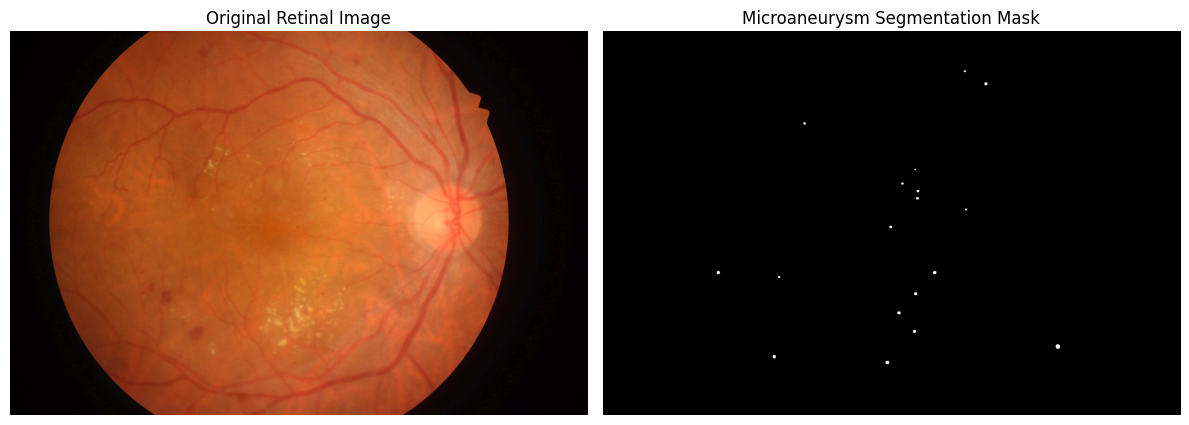

Unique mask pixel values: [0 1]


In [38]:
# Step 30: Visualize Original Image and Segmentation Mask

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os

image_path = os.path.join(image_folder, image_file)
mask_path = os.path.join(mask_folder, mask_file)

original = np.array(Image.open(image_path))
mask = np.array(Image.open(mask_path))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Retinal Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Microaneurysm Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Unique mask pixel values:", np.unique(mask))

Mask shape: (2848, 4288)
Data type: uint8
Number of unique pixel values: 2
First 20 unique values: [0 1]


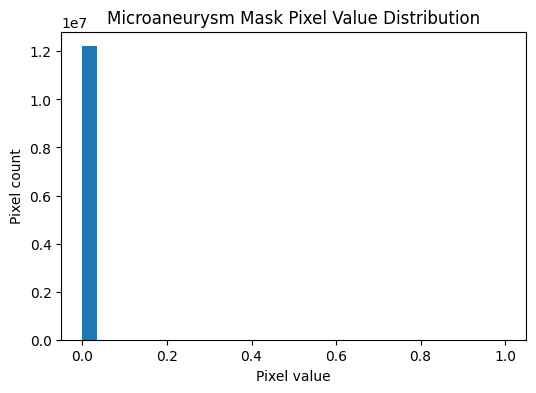

In [39]:
# Step 31: Inspect Segmentation Mask Pixel Values

print("Mask shape:", mask.shape)
print("Data type:", mask.dtype)
print("Number of unique pixel values:", len(np.unique(mask)))
print("First 20 unique values:", np.unique(mask)[:20])

plt.figure(figsize=(6, 4))
plt.hist(mask.ravel(), bins=30)
plt.title("Microaneurysm Mask Pixel Value Distribution")
plt.xlabel("Pixel value")
plt.ylabel("Pixel count")
plt.show()

**Phase 2 — Exploratory Data Analysis (EDA)**

In [40]:
# Step 32: Import Libraries and Inspect Dataset

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining data types:")
print(train_df.dtypes)

print("\nTraining sample:")
display(train_df.head())

Training shape: (413, 5)
Testing shape: (103, 5)

Training columns:
['Image name', 'Retinopathy grade', 'Risk of macular edema', 'filename', 'image_path']

Training data types:
Image name               object
Retinopathy grade         int64
Risk of macular edema     int64
filename                 object
image_path               object
dtype: object

Training sample:


,Image name,Retinopathy grade,Risk of macular edema,filename,image_path
0,IDRiD_001,3,2,IDRiD_001.jpg,/content/iris_data/extracted/B.%20Disease%20Gr...
1,IDRiD_002,3,2,IDRiD_002.jpg,/content/iris_data/extracted/B.%20Disease%20Gr...
2,IDRiD_003,2,2,IDRiD_003.jpg,/content/iris_data/extracted/B.%20Disease%20Gr...
3,IDRiD_004,3,2,IDRiD_004.jpg,/content/iris_data/extracted/B.%20Disease%20Gr...
4,IDRiD_005,4,0,IDRiD_005.jpg,/content/iris_data/extracted/B.%20Disease%20Gr...


Retinopathy grade
0    134
1     20
2    136
3     74
4     49
Name: count, dtype: int64


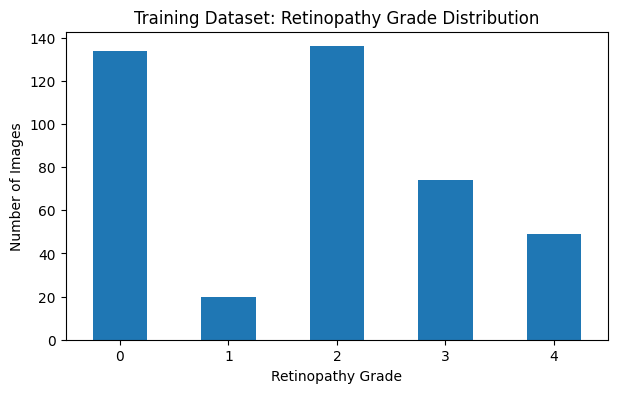

In [41]:
# Step 33: Retinopathy Grade Distribution

grade_counts = train_df["Retinopathy grade"].value_counts().sort_index()

print(grade_counts)

grade_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Training Dataset: Retinopathy Grade Distribution")
plt.xlabel("Retinopathy Grade")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

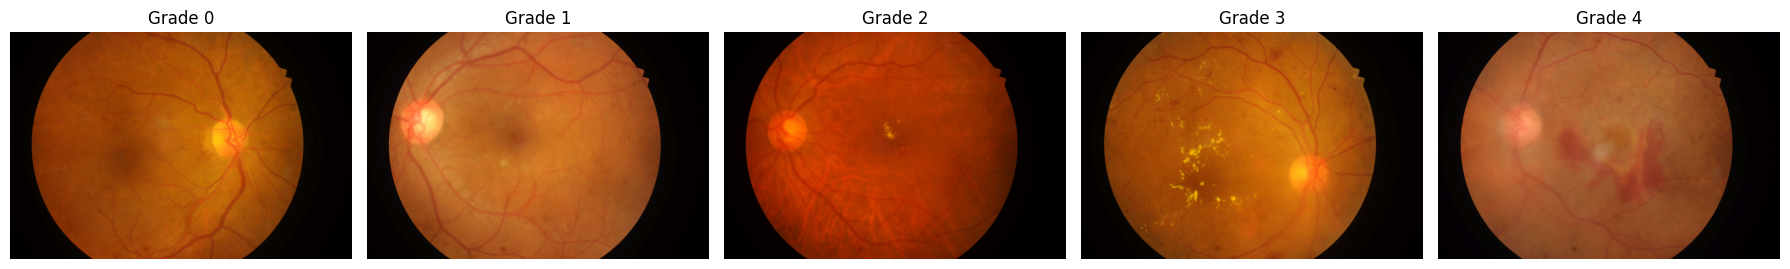

In [42]:
# Step 34: Display Images from Each Grade

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for grade in range(5):
    sample = train_df[train_df["Retinopathy grade"] == grade].iloc[0]
    image = Image.open(sample["image_path"]).convert("RGB")

    axes[grade].imshow(image)
    axes[grade].set_title(f"Grade {grade}")
    axes[grade].axis("off")

plt.tight_layout()
plt.show()

In [43]:
# Step 35: Grade Percentages

grade_percentages = (
    train_df["Retinopathy grade"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(grade_percentages.round(2))

Retinopathy grade
0    32.45
1     4.84
2    32.93
3    17.92
4    11.86
Name: proportion, dtype: float64


**Phase 3 — Image Preprocessing**

In [44]:
# Step 36: Image Preprocessing Configuration

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_CLASSES = 5

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 16
Number of classes: 5


Original size: (4288, 2848)
Resized size: (224, 224)


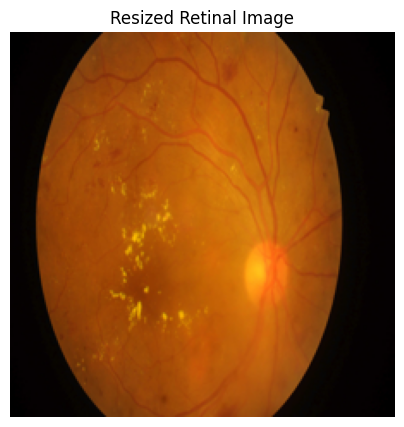

In [45]:
# Step 37: Resize a Retinal Image

sample_path = train_df.iloc[0]["image_path"]

original_image = Image.open(sample_path).convert("RGB")
resized_image = original_image.resize(IMG_SIZE)

print("Original size:", original_image.size)
print("Resized size:", resized_image.size)

plt.figure(figsize=(5, 5))
plt.imshow(resized_image)
plt.title("Resized Retinal Image")
plt.axis("off")
plt.show()

In [46]:
# Step 38: Inspect Pixel Values

image_array = np.array(resized_image)

print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Shape: (224, 224, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


**Phase 4 — Prepare the Classification Dataset**

In [47]:
# Step 39: Investigate Overlapping Image IDs

train_ids = set(train_df["Image name"].astype(str))
test_ids = set(test_df["Image name"].astype(str))

print("Training images:", len(train_ids))
print("Testing images:", len(test_ids))
print("Overlapping IDs:", len(train_ids & test_ids))

overlap = sorted(train_ids & test_ids)
print("First overlapping IDs:", overlap[:10])

Training images: 413
Testing images: 103
Overlapping IDs: 103
First overlapping IDs: ['IDRiD_001', 'IDRiD_002', 'IDRiD_003', 'IDRiD_004', 'IDRiD_005', 'IDRiD_006', 'IDRiD_007', 'IDRiD_008', 'IDRiD_009', 'IDRiD_010']


In [48]:
# Step 40: Create Training and Validation Splits

from sklearn.model_selection import train_test_split

train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["Retinopathy grade"]
)

print("Training samples:", len(train_part))
print("Validation samples:", len(val_part))
print("Training grade counts:")
print(train_part["Retinopathy grade"].value_counts().sort_index())
print("Validation grade counts:")
print(val_part["Retinopathy grade"].value_counts().sort_index())

Training samples: 330
Validation samples: 83
Training grade counts:
Retinopathy grade
0    107
1     16
2    109
3     59
4     39
Name: count, dtype: int64
Validation grade counts:
Retinopathy grade
0    27
1     4
2    27
3    15
4    10
Name: count, dtype: int64


In [49]:
# Step 41: Build TensorFlow Input Pipeline

import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["Retinopathy grade"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.shuffle(len(dataframe), seed=42)

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_part, training=True)
val_ds = make_dataset(val_part)
test_ds = make_dataset(test_df)

print("Datasets prepared.")

Datasets prepared.


In [50]:
# Step 42: Simple CNN Baseline

from tensorflow.keras import layers, models

baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 32s 539ms/step - accuracy: 0.2697 - loss: 1.5623 - val_accuracy: 0.4578 - val_loss: 1.4708
Epoch 2/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 17s 189ms/step - accuracy: 0.3727 - loss: 1.4641 - val_accuracy: 0.4578 - val_loss: 1.4425
Epoch 3/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 19s 277ms/step - accuracy: 0.4394 - loss: 1.4107 - val_accuracy: 0.4578 - val_loss: 1.3943
Epoch 4/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 16s 157ms/step - accuracy: 0.4242 - loss: 1.3593 - val_accuracy: 0.4819 - val_loss: 1.4286
Epoch 5/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 19s 277ms/step - accuracy: 0.4455 - loss: 1.3837 - val_accuracy: 0.4096 - val_loss: 1.4560


**Phase 6 — EfficientNetB0 Classification**

In [51]:
# Step 43: Load EfficientNetB0

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 loaded.


In [52]:
# Step 44: Build IRIS Classification Model

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs, name="IRIS_EfficientNetB0")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "IRIS_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [53]:
# Step 45: Train EfficientNetB0

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "iris_best_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.3303 - loss: 1.4790 - val_accuracy: 0.5181 - val_loss: 1.2701
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 21s 322ms/step - accuracy: 0.4727 - loss: 1.2286 - val_accuracy: 0.6024 - val_loss: 1.1325
Epoch 3/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 18s 238ms/step - accuracy: 0.4909 - loss: 1.1500 - val_accuracy: 0.6024 - val_loss: 1.0695
Epoch 4/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 19s 236ms/step - accuracy: 0.5182 - loss: 1.1078 - val_accuracy: 0.6988 - val_loss: 1.0410
Epoch 5/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 23s 322ms/step - accuracy: 0.5727 - loss: 1.0589 - val_accuracy: 0.6747 - val_loss: 1.0237
Epoch 6/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 17s 202ms/step - accuracy: 0.5545 - loss: 1.0286 - val_accuracy: 0.6386 - val_loss: 1.0133
Epoch 7/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 323ms/step - accuracy: 0.5818 - loss: 1.0197 - val_accuracy: 0.7108 - val_loss: 0.9918
Epoch 8/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 322ms/step - accuracy: 0.5970 - loss: 0.9817 - val_accurac

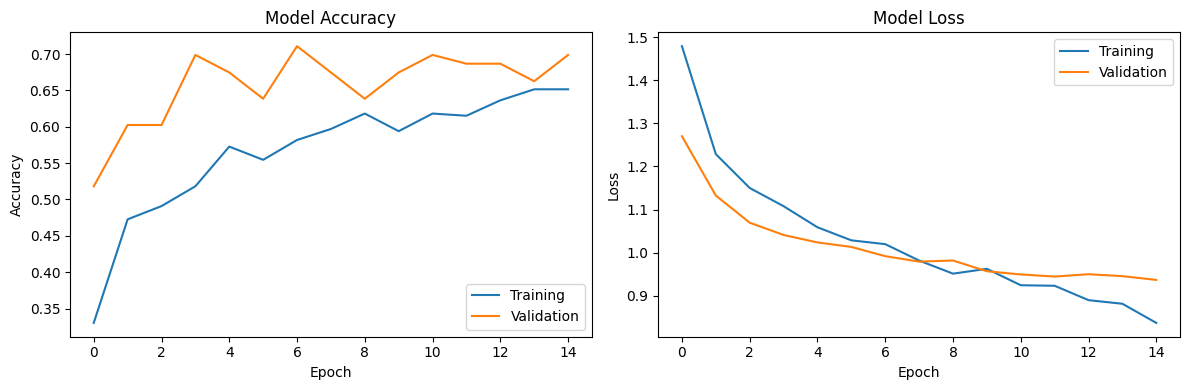

In [54]:
# Step 46: Plot Accuracy and Loss

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

**Phase 7 — Model Evaluation**

In [55]:
# Step 48: Evaluate the Model

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.5340 - loss: 1.1119
Test loss: 1.1119
Test accuracy: 0.534


In [56]:
# Step 49: Predict Test Grades

y_true = test_df["Retinopathy grade"].astype(int).to_numpy()
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("True labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])

7/7 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step
True labels: [4 4 4 4 4 3 3 2 2 2]
Predicted labels: [4 2 2 0 0 2 2 2 2 0]


In [57]:
# Step 50: Classification Report

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.70      0.68      0.69        34
           1       0.00      0.00      0.00         5
           2       0.45      0.78      0.57        32
           3       0.50      0.21      0.30        19
           4       0.50      0.23      0.32        13

    accuracy                           0.53       103
   macro avg       0.43      0.38      0.37       103
weighted avg       0.52      0.53      0.50       103



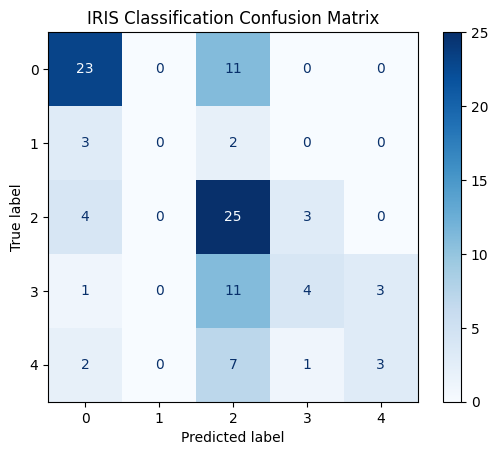

In [58]:
# Step 51: Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

display_cm.plot(cmap="Blues")
plt.title("IRIS Classification Confusion Matrix")
plt.show()

In [59]:
# Step 52: Save the Final Model

model.save("IRIS_EfficientNetB0.keras")
print("Model saved.")

Model saved.


**Phase 8 — Grad-CAM Explainability**

In [60]:
# Step 53: Find the Final Convolutional Layer

for layer in reversed(base_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        print("Candidate layer:", layer.name)
        break

Candidate layer: top_conv


In [65]:
#54: Rebuild Grad-CAM Model

import tensorflow as tf
import numpy as np

# Find the last convolutional layer inside EfficientNetB0
last_conv_layer = None

for layer in reversed(base_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer
        break

if last_conv_layer is None:
    raise ValueError("No convolutional layer found.")

print("Last convolutional layer:", last_conv_layer.name)

# Build a feature-extraction model from EfficientNetB0
feature_model = tf.keras.Model(
    inputs=base_model.inputs,
    outputs=[
        base_model.get_layer(last_conv_layer.name).output,
        base_model.output
    ]
)

print("Feature model created successfully.")

Last convolutional layer: top_conv
Feature model created successfully.


In [66]:
# Fix Step 55: Generate Grad-CAM Heatmap

def make_gradcam(image_tensor):
    image_tensor = tf.cast(image_tensor, tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, features = feature_model(
            image_tensor, training=False
        )

        # Pass the extracted features through the classification head
        x = features

        for layer in model.layers:
            if layer.name == base_model.name:
                continue
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue

            x = layer(x, training=False)

        predictions = x
        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError(
            "Gradients are None. Please check the model connections."
        )

    weights = tf.reduce_mean(grads, axis=(1, 2))
    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights[0], axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), int(class_index), predictions[0].numpy()

print("Grad-CAM function updated successfully.")

Grad-CAM function updated successfully.


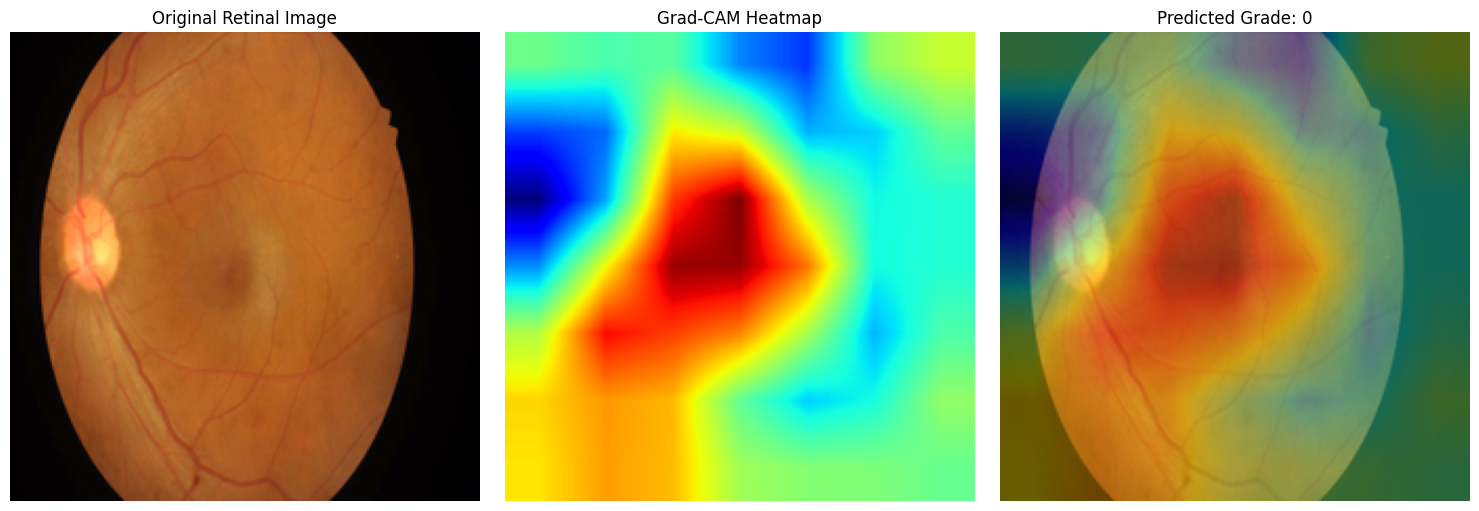

Predicted grade: 0
Class probabilities: [0.512  0.1738 0.2187 0.0813 0.0142]


In [67]:
# Fix Step 56: Visualize Grad-CAM

sample_path = train_part.iloc[0]["image_path"]

img = Image.open(sample_path).convert("RGB").resize(IMG_SIZE)
img_array = np.array(img, dtype=np.float32)
input_tensor = tf.expand_dims(img_array, axis=0)

heatmap, predicted_grade, probabilities = make_gradcam(input_tensor)

heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis], IMG_SIZE
).numpy().squeeze()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Retinal Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(f"Predicted Grade: {predicted_grade}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Predicted grade:", predicted_grade)
print("Class probabilities:", np.round(probabilities, 4))

**Phase 9 — U-Net Segmentation**

In [68]:
# Step 56: Create Microaneurysm Image-Mask Pairs

SEG_IMG_SIZE = (256, 256)
SEG_BATCH_SIZE = 4

seg_train_folder = os.path.join(
    SEGMENTATION_PATH, "1. Original Images", "a. Training Set"
)

seg_train_mask_folder = os.path.join(
    SEGMENTATION_PATH,
    "2. All Segmentation Groundtruths",
    "a. Training Set",
    "1. Microaneurysms"
)

seg_pairs = []

for filename in sorted(os.listdir(seg_train_folder)):
    if not filename.lower().endswith(".jpg"):
        continue

    image_id = os.path.splitext(filename)[0]
    mask_name = image_id + "_MA.tif"
    mask_path = os.path.join(seg_train_mask_folder, mask_name)

    if os.path.exists(mask_path):
        seg_pairs.append((
            os.path.join(seg_train_folder, filename),
            mask_path
        ))

print("Matched training pairs:", len(seg_pairs))
print("First pair:", seg_pairs[0] if seg_pairs else "No pairs found")

Matched training pairs: 54
First pair: ('/content/iris_data/extracted/A.%20Segmentation/A. Segmentation/1. Original Images/a. Training Set/IDRiD_01.jpg', '/content/iris_data/extracted/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms/IDRiD_01_MA.tif')


In [69]:
# Step 57: Split Segmentation Dataset

from sklearn.model_selection import train_test_split

seg_train_pairs, seg_val_pairs = train_test_split(
    seg_pairs,
    test_size=0.20,
    random_state=42
)

print("Segmentation training pairs:", len(seg_train_pairs))
print("Segmentation validation pairs:", len(seg_val_pairs))

Segmentation training pairs: 43
Segmentation validation pairs: 11


In [78]:

# Step 58 (Fixed): Load JPEG Images and TIFF Masks for U-Net

import tensorflow as tf
import numpy as np
from PIL import Image
import io

def load_segmentation_pair(image_path, mask_path):
    # Decode original retinal image (JPEG)
    image_data = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image_data, channels=3)
    image = tf.image.resize(image, SEG_IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    # Load TIFF mask using PIL via a TensorFlow Python callback
    def read_tiff_mask(path):
        path = path.numpy().decode("utf-8")
        with Image.open(path) as mask_img:
            mask_img = mask_img.convert("L")
            mask_array = np.array(mask_img, dtype=np.uint8)
        return mask_array

    mask = tf.py_function(
        func=read_tiff_mask,
        inp=[mask_path],
        Tout=tf.uint8
    )

    # Restore shape information lost by tf.py_function
    mask.set_shape([None, None,] if False else [None, None])
    mask = mask[..., tf.newaxis]

    # Resize using nearest-neighbor to preserve mask labels
    mask = tf.image.resize(
        mask, SEG_IMG_SIZE, method="nearest"
    )

    # Convert mask to binary values
    mask = tf.cast(mask > 0, tf.float32)

    return image, mask


def make_seg_dataset(pairs, training=False):
    image_paths = [p[0] for p in pairs]
    mask_paths = [p[1] for p in pairs]

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    ds = ds.map(
        load_segmentation_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(len(pairs), seed=42)

    return ds.batch(SEG_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# Recreate datasets
seg_train_ds = make_seg_dataset(seg_train_pairs, training=True)
seg_val_ds = make_seg_dataset(seg_val_pairs)

print("Segmentation datasets recreated successfully.")


Segmentation datasets recreated successfully.


In [79]:
# Step 59: Build U-Net

def unet_model(input_shape=(256, 256, 3)):
    inputs = layers.Input(input_shape)

    c1 = layers.Conv2D(16, 3, activation="relu", padding="same")(inputs)
    c1 = layers.Conv2D(16, 3, activation="relu", padding="same")(c1)
    p1 = layers.MaxPooling2D()(c1)

    c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(p1)
    c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(c2)
    p2 = layers.MaxPooling2D()(c2)

    c3 = layers.Conv2D(64, 3, activation="relu", padding="same")(p2)
    c3 = layers.Conv2D(64, 3, activation="relu", padding="same")(c3)
    p3 = layers.MaxPooling2D()(c3)

    b = layers.Conv2D(128, 3, activation="relu", padding="same")(p3)
    b = layers.Conv2D(128, 3, activation="relu", padding="same")(b)

    u3 = layers.UpSampling2D()(b)
    u3 = layers.Concatenate()([u3, c3])
    c4 = layers.Conv2D(64, 3, activation="relu", padding="same")(u3)
    c4 = layers.Conv2D(64, 3, activation="relu", padding="same")(c4)

    u2 = layers.UpSampling2D()(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = layers.Conv2D(32, 3, activation="relu", padding="same")(u2)
    c5 = layers.Conv2D(32, 3, activation="relu", padding="same")(c5)

    u1 = layers.UpSampling2D()(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = layers.Conv2D(16, 3, activation="relu", padding="same")(u1)
    c6 = layers.Conv2D(16, 3, activation="relu", padding="same")(c6)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c6)

    return models.Model(inputs, outputs, name="IRIS_UNet")

unet = unet_model()
unet.summary()

Model: "IRIS_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_4[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │      2,320 │ conv2d_18[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 128, 128,  │          0 │ conv2d_19[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_5[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_20[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ conv2d_21[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_22[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ conv2d_23[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_24[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 64, 64,    │          0 │ conv2d_25[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 64, 64,    │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 192)              │            │ conv2d_23[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 64, 64,    │    110,656 │ concatenate_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_26[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 128, 128,  │          0 │ conv2d_27[0][0] 

 Total params: 487,297 (1.86 MB)

 Trainable params: 487,297 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

In [80]:
# Step 60: Train U-Net

unet.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

unet_history = unet.fit(
    seg_train_ds,
    validation_data=seg_val_ds,
    epochs=10
)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9725 - loss: 0.3357 - val_accuracy: 0.9985 - val_loss: 0.2519
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - accuracy: 0.9990 - loss: 0.0491 - val_accuracy: 0.9985 - val_loss: 0.0212
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 148ms/step - accuracy: 0.9990 - loss: 0.0139 - val_accuracy: 0.9985 - val_loss: 0.0143
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 179ms/step - accuracy: 0.9990 - loss: 0.0092 - val_accuracy: 0.9985 - val_loss: 0.0126
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 179ms/step - accuracy: 0.9990 - loss: 0.0084 - val_accuracy: 0.9985 - val_loss: 0.0124
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.9990 - loss: 0.0078 - val_accuracy: 0.9985 - val_loss: 0.0122
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.9990 - loss: 0.0074 - val_accuracy: 0.9985 - val_loss: 0.0118
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 182ms/step - accuracy: 0.9990 - loss: 0.0073 - val_accuracy: 0.9

In [81]:
# Step 61: Save Segmentation Model

unet.save("IRIS_UNet_Microaneurysms.keras")
print("U-Net saved.")

U-Net saved.


**Phase 10 — Prediction and Segmentation Visualization**

In [82]:
# Step 62: Predict a Retinopathy Grade

def predict_grade(image_path):
    img = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    arr = np.array(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)

    probabilities = model.predict(arr, verbose=0)[0]
    grade = int(np.argmax(probabilities))

    return grade, probabilities

sample_path = train_part.iloc[0]["image_path"]
grade, probabilities = predict_grade(sample_path)

print("Predicted grade:", grade)
print("Class probabilities:", np.round(probabilities, 4))

Predicted grade: 0
Class probabilities: [0.512  0.1738 0.2187 0.0813 0.0142]


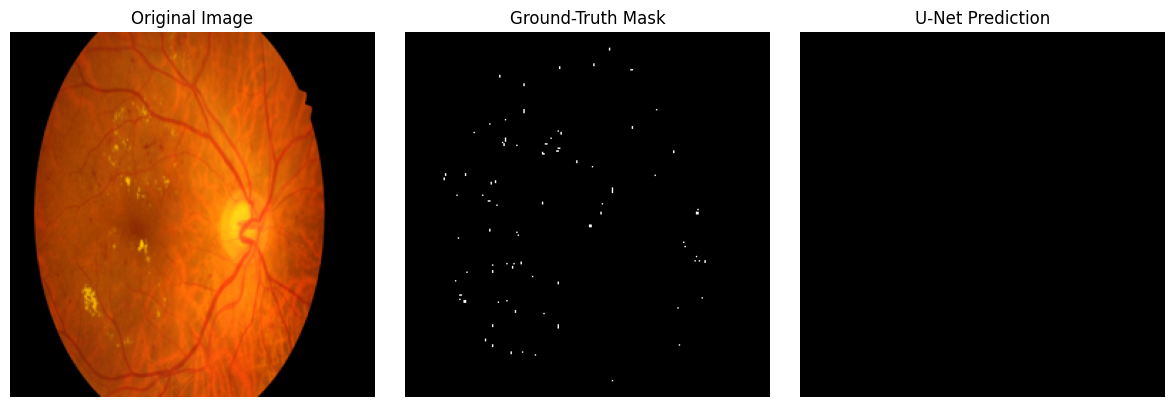

In [83]:
# Step 63: Display U-Net Segmentation Prediction

sample_image_path, sample_mask_path = seg_val_pairs[0]

image = Image.open(sample_image_path).convert("RGB").resize(SEG_IMG_SIZE)
mask = Image.open(sample_mask_path).convert("L").resize(
    SEG_IMG_SIZE, resample=Image.Resampling.NEAREST
)

image_array = np.array(image, dtype=np.float32) / 255.0
mask_array = np.array(mask)

prediction = unet.predict(
    np.expand_dims(image_array, axis=0),
    verbose=0
)[0, :, :, 0]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_array > 0, cmap="gray")
plt.title("Ground-Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction >= 0.5, cmap="gray")
plt.title("U-Net Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [84]:

# Step 64: Check IRIS Model Status

print("Classification model exists:", "model" in globals())
print("U-Net model exists:", "unet" in globals())

if "model" in globals():
    print("\nClassification model:")
    model.summary()

if "unet" in globals():
    print("\nU-Net model:")
    print("Input shape:", unet.input_shape)
    print("Output shape:", unet.output_shape)


Classification model exists: True
U-Net model exists: True

Classification model:


Model: "IRIS_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,068,788 (15.52 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 12,812 (50.05 KB)


U-Net model:
Input shape: (None, 256, 256, 3)
Output shape: (None, 256, 256, 1)


In [85]:

# Step 65: Save IRIS Classification and Segmentation Models

import os

MODEL_DIR = "/content/iris_models"
os.makedirs(MODEL_DIR, exist_ok=True)

CLASSIFIER_PATH = os.path.join(
    MODEL_DIR, "iris_classifier.keras"
)
UNET_PATH = os.path.join(
    MODEL_DIR, "iris_unet.keras"
)

model.save(CLASSIFIER_PATH)
unet.save(UNET_PATH)

print("Models saved successfully!")
print("Classification model:", CLASSIFIER_PATH)
print("U-Net model:", UNET_PATH)

print("\nFile sizes:")
print("Classifier:", round(os.path.getsize(CLASSIFIER_PATH) / (1024**2), 2), "MB")
print("U-Net:", round(os.path.getsize(UNET_PATH) / (1024**2), 2), "MB")


Models saved successfully!
Classification model: /content/iris_models/iris_classifier.keras
U-Net model: /content/iris_models/iris_unet.keras

File sizes:
Classifier: 16.33 MB
U-Net: 5.69 MB


In [87]:

# Step 66: Download IRIS Models Without Google Drive

from google.colab import files
import os

print("Classifier exists:", os.path.exists(CLASSIFIER_PATH))
print("U-Net exists:", os.path.exists(UNET_PATH))

if os.path.exists(CLASSIFIER_PATH) and os.path.exists(UNET_PATH):
    print("Downloading classification model...")
    files.download(CLASSIFIER_PATH)

    print("Downloading U-Net model...")
    files.download(UNET_PATH)
else:
    print("Model files not found. Please rerun Step 65 first.")


Classifier exists: True
U-Net exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:

# Step 64: Upload trained IRIS models into Google Colab

from google.colab import files

uploaded_models = files.upload()

print("Uploaded files:")
for filename in uploaded_models:
    print(filename)


Saving iris_classifier.keras to iris_classifier.keras
Saving iris_unet.keras to iris_unet.keras
Uploaded files:
iris_classifier.keras
iris_unet.keras


In [89]:

# Step 65: Load saved IRIS models

import tensorflow as tf
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os

CLASSIFIER_PATH = "/content/iris_classifier.keras"
UNET_PATH = "/content/iris_unet.keras"

model = tf.keras.models.load_model(CLASSIFIER_PATH)
unet = tf.keras.models.load_model(UNET_PATH)

print("IRIS classification model loaded!")
print("IRIS U-Net model loaded!")


IRIS classification model loaded!
IRIS U-Net model loaded!


Saving IDRiD_07.jpg to IDRiD_07.jpg


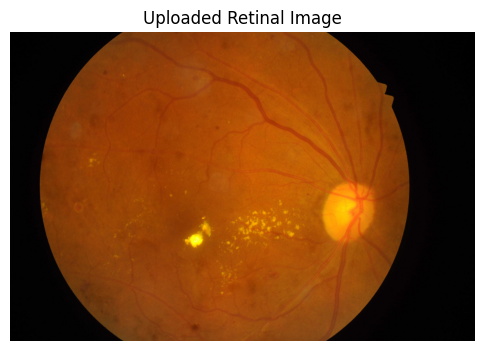

Predicted grade: 2
Predicted result: Moderate diabetic retinopathy

Class probabilities:
Grade 0: 4.61%
Grade 1: 1.01%
Grade 2: 44.86%
Grade 3: 36.81%
Grade 4: 12.71%


In [90]:

# Step 66: Upload and classify a retinal fundus image

from google.colab import files

uploaded_image = files.upload()

image_filename = next(iter(uploaded_image))
image = Image.open(image_filename).convert("RGB")

# Display uploaded image
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Uploaded Retinal Image")
plt.axis("off")
plt.show()

# Preprocess exactly to the classifier input size
resized_image = image.resize((224, 224))
image_array = np.asarray(resized_image, dtype=np.float32)
input_array = np.expand_dims(image_array, axis=0)

# Predict
probabilities = model.predict(input_array, verbose=0)[0]
predicted_grade = int(np.argmax(probabilities))

grade_names = {
    0: "No diabetic retinopathy",
    1: "Mild diabetic retinopathy",
    2: "Moderate diabetic retinopathy",
    3: "Severe diabetic retinopathy",
    4: "Proliferative diabetic retinopathy"
}

print("Predicted grade:", predicted_grade)
print("Predicted result:", grade_names[predicted_grade])
print("\nClass probabilities:")

for grade, probability in enumerate(probabilities):
    print(f"Grade {grade}: {probability * 100:.2f}%")


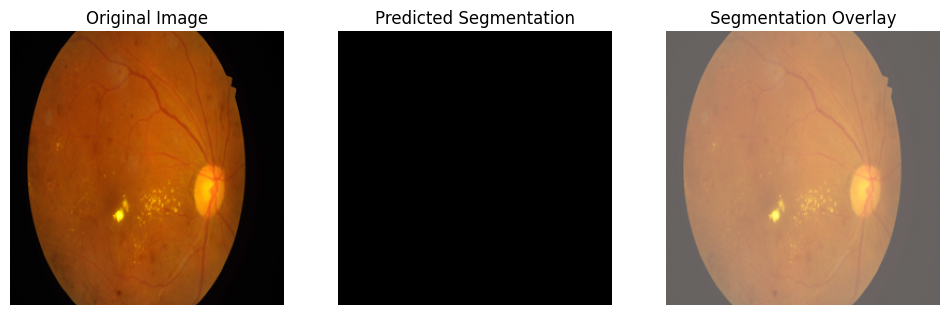

In [91]:

# Step 67: Generate U-Net segmentation prediction

seg_image = image.resize((256, 256))
seg_array = np.asarray(seg_image, dtype=np.float32) / 255.0
seg_input = np.expand_dims(seg_array, axis=0)

seg_prediction = unet.predict(seg_input, verbose=0)[0, :, :, 0]
seg_mask = seg_prediction >= 0.5

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(seg_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(seg_mask, cmap="gray")
plt.title("Predicted Segmentation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(seg_image)
plt.imshow(seg_mask, cmap="Reds", alpha=0.4)
plt.title("Segmentation Overlay")
plt.axis("off")

plt.show()


In [92]:
import os

os.makedirs("/content/gradcam_visualizations", exist_ok=True)
os.makedirs("/content/segmentation_results", exist_ok=True)

print("Output folders created!")

Output folders created!


In [93]:
os.makedirs("/content/gradcam_visualizations", exist_ok=True)

plt.savefig(
    "/content/gradcam_visualizations/gradcam_sample.png",
    bbox_inches="tight",
    dpi=150
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [95]:
os.makedirs("/content/segmentation_results", exist_ok=True)

plt.savefig(
    "/content/segmentation_results/segmentation_sample.png",
    bbox_inches="tight",
    dpi=150
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [97]:
import shutil

shutil.make_archive(
    "/content/gradcam_visualizations", "zip",
    "/content/gradcam_visualizations"
)

shutil.make_archive(
    "/content/segmentation_results", "zip",
    "/content/segmentation_results"
)

from google.colab import files

files.download("/content/gradcam_visualizations.zip")
files.download("/content/segmentation_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Conclusion**

This project, **IRIS – Eye Disease Detection Using Deep Learning**, applies deep learning techniques to analyze retinal fundus images for diabetic retinopathy severity classification and lesion segmentation.

**Classification Using EfficientNet-B0**

EfficientNet-B0 was implemented to classify retinal images into five diabetic retinopathy severity grades, ranging from Grade 0 (No Diabetic Retinopathy) to Grade 4 (Proliferative Diabetic Retinopathy). The model generates class probabilities to support the prediction process.

**Lesion Segmentation Using U-Net**

U-Net was implemented to generate pixel-level segmentation masks from retinal images. This component aims to highlight potential lesion regions and support visual analysis of retinal abnormalities.

**Grad-CAM Visualization**

Grad-CAM was incorporated to visualize image regions that influence the classification model's predictions, improving the interpretability of its outputs.

**Key Insights**

- EfficientNet-B0 provides a deep learning approach for classifying diabetic retinopathy severity from retinal fundus images.
- U-Net enables pixel-level segmentation to support the analysis of potential retinal lesions.
- Grad-CAM provides visual explanations of the regions influencing classification predictions.
- Combining classification, segmentation, and explainability creates a more comprehensive experimental retinal image analysis workflow.
- Model validation is essential to assess generalization and prediction reliability.

**Overall Outcome**

The project demonstrates how deep learning techniques can be combined for retinal image classification, lesion segmentation, and visual explanation. It provides a foundation for an experimental eye disease analysis application that accepts retinal images and displays model predictions. Further validation using appropriate independent datasets and clinical expertise is required before any real-world diagnostic use.